# LLM Companion Notebook: GPT-2 on HuggingFace

**COMP 395 — Deep Learning**

In this companion activity, you will load GPT-2 — a decoder-only transformer — and experiment with text generation. This is the same family of architecture behind ChatGPT, Claude, and other modern LLMs, just far smaller (124M parameters; today's largest models are orders of magnitude bigger, and most labs don't publish exact counts).

**Connection to prior work:** You used HuggingFace `transformers` in the BERT assignment with DistilBERT (an *encoder*). GPT-2 is the other side: a *decoder* that generates text left-to-right.

## Setup

In [1]:
# Imports
import torch
import torch.nn.functional as F
import os

# Device selection — same pattern from your earlier labs
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {device}")

# Verify transformers is installed
import transformers
print(f"Transformers version: {transformers.__version__}")
print("\n✅ Imports successful.")

PyTorch version: 2.10.0+cu130
Using device: cuda


f:\Dev\COMP395\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Transformers version: 5.22.1

✅ Imports successful.


## Part 1: Load GPT-2 and Generate Text

GPT-2 is a **decoder-only transformer** pretrained on WebText (40 GB of internet text). Its only training objective was **next-token prediction** — the same cross-entropy loss you used in Labs 5 and 6, just applied to a vocabulary of ~50,000 tokens.

We load the smallest GPT-2 (124M parameters, ~500 MB). If the cell below crashes your kernel, try closing other applications to free memory.

In [2]:
from transformers import GPT2LMHeadModel, GPT2Tokenizer

# Load tokenizer first (tiny, won't crash)
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
print("Tokenizer loaded.")

# Load model and move to device
model = GPT2LMHeadModel.from_pretrained(
    "gpt2",
    low_cpu_mem_usage=True,
    torch_dtype=torch.float32
).to(device)
model.eval()
print(f"Model loaded on {device}.")

# GPT-2 has no separate pad token — set it to eos to suppress warnings
tokenizer.pad_token = tokenizer.eos_token
model.config.pad_token_id = model.config.eos_token_id

print(f"\nModel parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Vocabulary size: {tokenizer.vocab_size:,}")
print(f"Max context length: {model.config.n_positions}")

W1113 13:51:10.540000 10544 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Tokenizer loaded.


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 410.56it/s]


Model loaded on cuda.

Model parameters: 124,439,808
Vocabulary size: 50,257
Max context length: 1024


**If the cell above crashes your kernel:**
1. Close other apps (browsers with many tabs are the usual culprit)
2. Restart the kernel and try again
3. If it keeps crashing, try clearing the HuggingFace cache: `rm -rf ~/.cache/huggingface/hub/models--gpt2` and re-run
4. As a last resort, you can use `torch_dtype=torch.float16` in the `from_pretrained` call to halve memory usage

### Exploring the Tokenizer

In Lab 6, you tokenized text by splitting on whitespace — each word became one token. GPT-2 uses **Byte Pair Encoding (BPE)**, a *subword* tokenizer. Common words stay whole, but rare words get split into pieces. This means there's no `<unk>` token — any text can be encoded.

In [3]:
# See how BPE tokenizes different kinds of text
examples = [
    "The cat sat on the mat",          # Common words
    "unforgettable",                    # Gets split into subwords
    " unforgettable",                   # Same word with a leading space (as it appears mid-sentence)
    "Pneumonoultramicroscopicsilicovolcanoconiosis",  # Very rare word
    "def fibonacci(n):",                # Code
    "GPT-2 has 50,257 tokens",          # Numbers and punctuation
]

for text in examples:
    token_ids = tokenizer.encode(text)
    tokens = [tokenizer.decode([tid]) for tid in token_ids]
    print(f"Text:   {text}")
    print(f"Tokens: {tokens}")
    print(f"Count:  {len(token_ids)} tokens")
    print()

Text:   The cat sat on the mat
Tokens: ['The', ' cat', ' sat', ' on', ' the', ' mat']
Count:  6 tokens

Text:   unforgettable
Tokens: ['un', 'for', 'gettable']
Count:  3 tokens

Text:    unforgettable
Tokens: [' unforgettable']
Count:  1 tokens

Text:   Pneumonoultramicroscopicsilicovolcanoconiosis
Tokens: ['P', 'neum', 'on', 'oult', 'ram', 'icro', 'sc', 'op', 'ics', 'ilic', 'ov', 'ol', 'can', 'ocon', 'iosis']
Count:  15 tokens

Text:   def fibonacci(n):
Tokens: ['def', ' fib', 'on', 'acci', '(', 'n', '):']
Count:  7 tokens

Text:   GPT-2 has 50,257 tokens
Tokens: ['G', 'PT', '-', '2', ' has', ' 50', ',', '257', ' tokens']
Count:  9 tokens



**🤔 Notice:** "The" and "the" are different tokens (capitalization matters), and so are "the" and " the" — a leading space is part of the token. Compare "unforgettable" with " unforgettable" above: the pieces follow frequency in the training data, not meaning. Common words like "the" are single tokens, but rare words get broken into subword pieces. When we say the model does "next-token prediction," it's predicting the next *subword* — not necessarily the next word.

**Connection to Lab 6:** Your whitespace tokenizer had a fixed vocabulary and mapped unknown words to `<unk>`. BPE can handle *any* input by falling back to smaller pieces — all the way down to individual bytes if needed.

In [4]:
# Simple generation with greedy decoding
prompt = "The capital of France is"
inputs = tokenizer(prompt, return_tensors="pt").to(device)

with torch.no_grad():
    output = model.generate(
        **inputs,
        max_new_tokens=50,
        do_sample=False  # Greedy: always pick the most probable token
    )

print("=== Greedy Decoding ===")
print(tokenizer.decode(output[0], skip_special_tokens=True))

=== Greedy Decoding ===
The capital of France is the capital of the French Republic, and the capital of the French Republic is the capital of the French Republic.

The French Republic is the capital of the French Republic.

The French Republic is the capital of the French Republic.




### Try your own prompts

Try a few different kinds of prompts and observe the behavior. Remember: GPT-2 is a pure next-token predictor trained on web text from before 2019. It has **no instruction tuning** — it doesn't know it's supposed to "answer" you.

In [5]:
# Try these prompts (or make your own)
prompts = [
    "What is the meaning of life?",           # Will it answer, or continue a list of questions?
    "def fibonacci(n):",                       # Can it write code?
    "In a shocking turn of events,",           # Creative/news style
    "The transformer architecture works by",   # Technical explanation
]

for prompt in prompts:
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=60, do_sample=False)
    print(f"\nPrompt: {prompt}")
    print(f"Output: {tokenizer.decode(output[0], skip_special_tokens=True)}")
    print("-" * 70)


Prompt: What is the meaning of life?
Output: What is the meaning of life?

The meaning of life is that we are living in a world that is not ours.

The meaning of life is that we are living in a world that is not ours.

The meaning of life is that we are living in a world that is not ours.

The
----------------------------------------------------------------------

Prompt: def fibonacci(n):
Output: def fibonacci(n):

return n

def fibonacci(n):

return n

def fibonacci(n):

return n

def fibonacci(n):

return n

def fibonacci(n):

return n

def fib
----------------------------------------------------------------------

Prompt: In a shocking turn of events,
Output: In a shocking turn of events, the FBI has now released a statement that says the FBI has "no evidence" that the Trump campaign colluded with Russia to influence the 2016 election.

The statement, released by the FBI on Friday, says that the FBI has "no evidence" that the Trump campaign colluded with Russia to
----------------

**🤔 Observe:** Did GPT-2 "answer" the question prompt, or did it do something else? Why?

**Answer:** For "What is the meaning of life?", GPT-2 produced an answer-like sentence about living in a world that is not ours, then repeated it. It continued a plausible text pattern instead of giving a useful, developed answer. Its training objective was to predict the next token in web text, without instruction tuning to teach it how to respond as an assistant.

*(This is the behavior gap that post-training — SFT and RLHF — was designed to fix.)*

### Does GPT-2 know the answer? Try a few-shot prompt

A base model continues patterns. If the prompt already *looks like* a list of questions with answers, the most likely continuation is another answer. This is called a **few-shot prompt**.

In [6]:
# Few-shot prompt: show the pattern, then leave the last answer blank
few_shot = (
    "Q: What is the capital of Germany?\n"
    "A: Berlin\n\n"
    "Q: What is the capital of Japan?\n"
    "A: Tokyo\n\n"
    "Q: What is the capital of France?\n"
    "A:"
)
inputs = tokenizer(few_shot, return_tensors="pt").to(device)
with torch.no_grad():
    output = model.generate(**inputs, max_new_tokens=5, do_sample=False)

# Print only the newly generated tokens
new_tokens = output[0][inputs["input_ids"].shape[1]:]
print("GPT-2 continues with:", repr(tokenizer.decode(new_tokens)))


GPT-2 continues with: ' Paris\n\nQ:'


**🤔 Observe:** Did the pattern change GPT-2's behavior? Compare with the bare question prompt above. Same weights, same knowledge — only the prompt changed. Try your own question at the end of the pattern.

**Answer:** Yes. The earlier capital-of-France completion repeated phrases about the French Republic without producing Paris. After the Germany/Berlin and Japan/Tokyo examples, GPT-2 generated ` Paris\n\nQ:`, giving the correct answer and then continuing the question-and-answer pattern. The prompt changed how it used its existing learned information; no weights were updated.

## Part 2: Decoding Strategies

The model outputs logits (raw scores) over the entire vocabulary at each step. How we convert those logits into a token choice dramatically affects the output.

### Under the Hood: What the Model Actually Outputs

In [7]:
# Let's look at what the model actually produces
prompt = "The best programming language is"
input_ids = tokenizer.encode(prompt, return_tensors="pt").to(device)

with torch.no_grad():
    outputs = model(input_ids)
    # outputs.logits shape: (batch=1, seq_len, vocab_size=50257)
    next_token_logits = outputs.logits[0, -1, :]  # logits for the NEXT token

# Convert to probabilities
probs = F.softmax(next_token_logits, dim=-1)

# Top 10 most likely next tokens
top_probs, top_indices = torch.topk(probs, 10)

print(f"Prompt: '{prompt}'")
print(f"\nTop 10 next-token predictions:")
print(f"{'Token':<15} {'Probability':>12}")
print("-" * 28)
for prob, idx in zip(top_probs, top_indices):
    token = tokenizer.decode([idx])
    print(f"{repr(token):<15} {prob.item():>12.4f}")

print(f"\nTotal probability mass in top 10: {top_probs.sum().item():.4f}")
print(f"Remaining mass: {1 - top_probs.sum().item():.4f}, spread over {len(probs) - 10:,} other tokens")
print(f"Tokens with probability above 0.0001: {(probs > 0.0001).sum().item()}")

Prompt: 'The best programming language is'

Top 10 next-token predictions:
Token            Probability
----------------------------
' Python'             0.0570
' Java'               0.0570
' the'                0.0531
' a'                  0.0401
' not'                0.0396
' C'                  0.0259
' one'                0.0248
' JavaScript'         0.0213
' Haskell'            0.0193
' probably'           0.0186

Total probability mass in top 10: 0.3566
Remaining mass: 0.6434, spread over 50,247 other tokens
Tokens with probability above 0.0001: 757


### Temperature

Temperature scales the logits before softmax: $P(x_i) = \frac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}$

This is the same softmax you've used since Lab 5 — just with a knob.

In [8]:
# Compare temperatures
prompt = "Once upon a time in a land far away,"
inputs = tokenizer(prompt, return_tensors="pt").to(device)

temperatures = [0.3, 0.7, 1.0, 1.5]

for temp in temperatures:
    print(f"\n=== Temperature = {temp} ===")
    # Generate 3 times to see variation
    for i in range(3):
        with torch.no_grad():
            output = model.generate(
                **inputs,
                max_new_tokens=40,
                do_sample=True,
                temperature=temp,
                top_k=0  # Turn OFF top-k. If you omit this, generate() silently applies top_k=50
            )
        text = tokenizer.decode(output[0], skip_special_tokens=True)
        # Show only the generated part
        generated = text[len(prompt):]
        print(f"  Run {i+1}: ...{generated[:80]}")


=== Temperature = 0.3 ===
  Run 1: ... the inhabitants of the land were called the "Shamanites." The Shamanites were t
  Run 2: ... a man was standing in the middle of the forest, with his head bowed, and his ey
  Run 3: ... a man was standing in the middle of a field, and he had a great deal of respect

=== Temperature = 0.7 ===
  Run 1: ... the gods have taken their course and are at war with us. Our kin are fighting. 
  Run 2: ... it was not at all uncommon to encounter enemies who were fully grown and able t
  Run 3: ... the earth and the heavens were shattered by thunder and lightning, and a fire w

=== Temperature = 1.0 ===
  Run 1: ... the River Nile flooded the areas around it with water that supposed to adhere a
  Run 2: ... the wizard knelt upon his stag'y, proud face. He questioned curiously into its 
  Run 3: ...

Malkave dawdles down on his heels

All the lot like his beautiful wife.

Far a

=== Temperature = 1.5 ===
  Run 1: ... barricades of NC4 trees awoke young Stalin

### Nucleus Sampling (Top-p)

Instead of keeping a fixed number of tokens (top-k), nucleus sampling keeps the smallest set of tokens whose cumulative probability ≥ p. This adapts to the model's confidence at each step.

In [9]:
# Nucleus sampling
prompt = "Artificial intelligence will"
inputs = tokenizer(prompt, return_tensors="pt").to(device)

configs = [
    {"name": "Greedy",            "do_sample": False},
    {"name": "Top-k (k=50)",      "do_sample": True, "top_k": 50, "temperature": 0.8},
    {"name": "Nucleus (p=0.95)",   "do_sample": True, "top_p": 0.95, "top_k": 0, "temperature": 0.8},
    {"name": "Nucleus (p=0.5)",    "do_sample": True, "top_p": 0.5,  "top_k": 0, "temperature": 0.8},
]

for config in configs:
    name = config["name"]
    gen_kwargs = {k: v for k, v in config.items() if k != "name"}
    print(f"\n=== {name} ===")
    for i in range(2):
        with torch.no_grad():
            output = model.generate(**inputs, max_new_tokens=50, **gen_kwargs)
        text = tokenizer.decode(output[0], skip_special_tokens=True)
        print(f"  Run {i+1}: {text[:120]}")


=== Greedy ===
  Run 1: Artificial intelligence will be able to do things like search for and find people, and to do things like find out who's 
  Run 2: Artificial intelligence will be able to do things like search for and find people, and to do things like find out who's 

=== Top-k (k=50) ===
  Run 1: Artificial intelligence will continue to be built into our lives for the foreseeable future, but there is still much mor
  Run 2: Artificial intelligence will change the way people think, perform, and speak.

It's hard to believe that, under the hood

=== Nucleus (p=0.95) ===
  Run 1: Artificial intelligence will be able to do amazing things. It has shown up in most industrial countries including Switze
  Run 2: Artificial intelligence will inevitably be able to gather data on us all and help us discern and solve problems with mor

=== Nucleus (p=0.5) ===
  Run 1: Artificial intelligence will not be able to create a world where people are better able to work together, because the wo
 

### Visualize the Nucleus

Let's see exactly which tokens fall inside the nucleus for a given step.

p=0.5: 23 tokens in the nucleus (out of 50,257)
p=0.9: 479 tokens in the nucleus (out of 50,257)
p=0.95: 1107 tokens in the nucleus (out of 50,257)
p=0.99: 4422 tokens in the nucleus (out of 50,257)


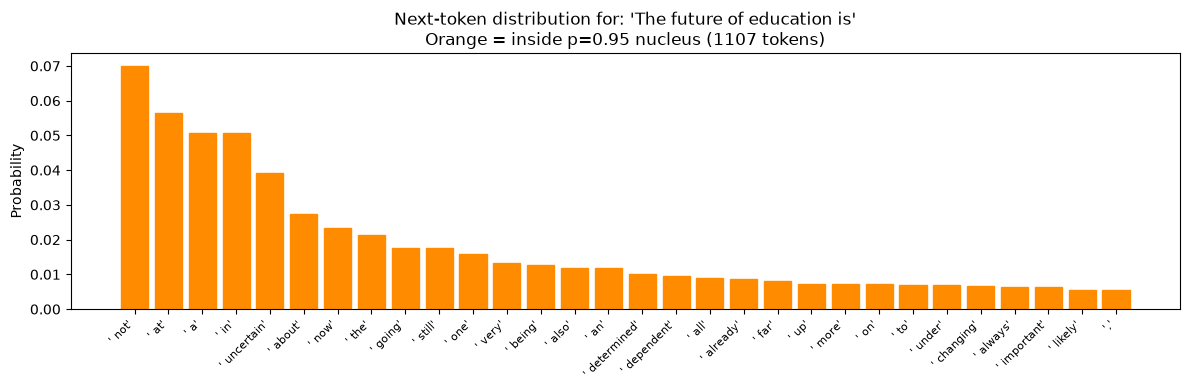

In [10]:
import matplotlib.pyplot as plt

prompt = "The future of education is"
input_ids = tokenizer.encode(prompt, return_tensors="pt").to(device)

with torch.no_grad():
    outputs = model(input_ids)
    logits = outputs.logits[0, -1, :]

probs = F.softmax(logits, dim=-1)
sorted_probs, sorted_indices = torch.sort(probs, descending=True)

# Cumulative probability
cumulative = torch.cumsum(sorted_probs, dim=0)

# How many tokens are in the nucleus for different p values?
for p in [0.5, 0.9, 0.95, 0.99]:
    n_tokens = (cumulative <= p).sum().item() + 1
    print(f"p={p}: {n_tokens} tokens in the nucleus (out of {len(probs):,})")

# Plot the top 30 tokens and the p=0.95 cutoff
n_show = 30
fig, ax = plt.subplots(figsize=(12, 4))
tokens = [repr(tokenizer.decode([idx])) for idx in sorted_indices[:n_show]]  # repr() makes leading spaces visible
bars = ax.bar(range(n_show), sorted_probs[:n_show].cpu().numpy(), color="steelblue")

# Color tokens inside p=0.95 nucleus
n_in_nucleus = (cumulative <= 0.95).sum().item() + 1
for i in range(min(n_in_nucleus, n_show)):
    bars[i].set_color("darkorange")

ax.set_xticks(range(n_show))
ax.set_xticklabels(tokens, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Probability")
ax.set_title(f"Next-token distribution for: '{prompt}'\nOrange = inside p=0.95 nucleus ({n_in_nucleus} tokens)")
plt.tight_layout()
plt.show()

## Part 3: Reflection

Answer these in your notebook (a few sentences each):

1. **Base model behavior:** When you gave GPT-2 a question like "What is...?", did it answer the question or do something else? Explain *why* based on what the model was trained on.

**Answer:** GPT-2 gave an answer-like sentence to "What is the meaning of life?", but then repeated the same sentence several times. Other outputs showed similar repetition: the Fibonacci example repeatedly returned `n`, and the transformer explanation repeated "single-ended." GPT-2 was pretrained to predict the next token in web text, so it learns likely continuations rather than being explicitly trained to give helpful, correct answers. Greedy decoding repeatedly chooses the most likely next token and can keep the model in these repetitive patterns.

2. **Sampling tradeoffs:** In your temperature experiments, what happened at very low temperatures vs. very high? Which setting would you want for (a) writing a creative story, (b) answering a factual question?

**Answer:** At temperature 0.3, the saved outputs were mostly coherent and conventional; two runs began with a man standing in a forest or field. At 1.5, the outputs became much less coherent, mixing unrelated ideas such as Stalin and martinis and producing malformed text. Lower temperature concentrates probability on the highest-scoring tokens, while higher temperature gives less likely tokens more chance. For a creative story, I would choose 0.7 in this experiment because it gave varied but readable scenes involving gods, enemies, and storms. For a factual question, I would choose a low temperature such as 0.3 or greedy decoding for consistency, but this does not guarantee correctness: the greedy capital-of-France output still failed to give Paris.

3. **Nucleus vs. top-k:** Look at your nucleus visualization. Why does nucleus sampling adapt better than a fixed top-k to different contexts? (Hint: think about what happens when the model is very confident vs. uncertain.)

**Answer:** For "The future of education is", the saved nucleus sizes were 23 tokens at p=0.5, 479 at p=0.9, 1,107 at p=0.95, and 4,422 at p=0.99. Nucleus sampling keeps enough of the highest-probability tokens to reach the chosen probability mass, so at a fixed p it can use a small set when the model is confident and a larger set when its probabilities are spread out. A fixed top-k always keeps the same number, which can admit unlikely tokens in a confident context or exclude plausible options in an uncertain one. At p=0.95, all 30 bars shown are inside the nucleus; the full set of 1,107 tokens extends beyond the plotted range.

4. **Connection to post-training:** The few-shot prompt changed what GPT-2 did without changing its weights. What does that tell you about *knowledge* vs. *behavior*? Why is prompting alone still not enough to turn GPT-2 into something like ChatGPT — what do SFT and RLHF add?

**Answer:** With the few-shot examples, GPT-2 generated ` Paris\n\nQ:`, whereas the earlier capital-of-France prompt produced repetitive text without naming Paris. This suggests that the relevant information was already available in its learned weights, but the prompt helped elicit it in the desired format. Prompting alone remains fragile: even this successful output continued with another `Q:`, and the other examples showed repetition and incorrect code. Supervised fine-tuning (SFT) updates the weights using examples of desired instruction-and-response behavior, while reinforcement learning from human feedback (RLHF) uses human preferences, often through a learned reward model, to favor more helpful and appropriate responses. These methods train more consistent assistant behavior across prompts, although they do not guarantee factual accuracy.

*Assistance note: These answers were drafted with AI assistance from the notebook's saved outputs. No new model runs were performed for these answers.*